In [32]:
pip install pandas_ta

In [33]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from uuid import uuid4
import pandas_ta as ta

In [142]:
start_date = '2024-01-01'
end_date = '2025-01-01'
# ticker = 'BTC-USD'
ticker ='XRP-USD'
# ticker = 'ETH-USD'
# ticker = 'SOL-USD'
data = pd.DataFrame(yf.download(ticker,start=start_date,end=end_date, interval = '1h', group_by = 'Tickers'))
data = data.droplevel(level=0, axis=1)
data

[*********************100%***********************]  1 of 1 completed


Price,Open,High,Low,Close,Volume
Datetime,,,,,
2024-01-01 00:00:00+00:00,0.614986,0.617478,0.614986,0.616168,0
2024-01-01 01:00:00+00:00,0.616167,0.618837,0.615820,0.618817,19452736
2024-01-01 02:00:00+00:00,0.618810,0.618810,0.616120,0.616137,0
2024-01-01 03:00:00+00:00,0.616120,0.616153,0.612977,0.613529,7601536
2024-01-01 04:00:00+00:00,0.613488,0.613925,0.611211,0.611914,20043392
...,...,...,...,...,...
2024-12-31 19:00:00+00:00,2.087931,2.089792,2.081342,2.088833,0
2024-12-31 20:00:00+00:00,2.088782,2.099136,2.088782,2.094896,0
2024-12-31 21:00:00+00:00,2.095240,2.098867,2.088542,2.095423,0


In [143]:
data['RSI'] = ta.rsi(data['Close'], length=14)


In [144]:
pd.options.mode.chained_assignment = None
def volume_profile(data, num_bins = 5):
  vp = data[['Close',  'Volume']]
  max_price = vp['Close'].max()
  min_price = vp['Close'].min()
  price_bins = np.linspace(min_price, max_price, num_bins)
  vp['bin_idx'] = np.digitize(vp['Close'], price_bins) -1
  grouped = vp.groupby('bin_idx')['Volume'].sum().sort_values(ascending=False)
  price_list = []
  for id in grouped.index:
    price_list.append(price_bins[id])

  price_list.sort()
  # print(price_list)
  return price_list




In [145]:
data['rets'] = data['Close'].pct_change()
data['signal'] = 0.0


In [146]:
look_back = 200
entry_price = 0
stoploss_price = 0
takeprofit_price = 0
rl_pnls = []
unrl_pnls = []
signal = 0
for i in range(look_back, len(data)):
  if signal ==0:
    window_data = data[i -look_back:i]
    price_list = volume_profile(window_data, round(look_back))
    largest = float('-inf')
    pre_value = None

    for j, price in enumerate(price_list):
      if price <= data['Close'].iloc[i] and price > largest:
        largest = price
        pre_value = price_list[j-1] if j > 0 else None
        next_value = price_list[j+2] if j < len(price_list) -2 else None

    signal = 1 if largest != float('-inf') else 0
    data['signal'].iloc[i] = signal

    stoploss_price = pre_value if pre_value is not None and pre_value > entry_price *0.9 else entry_price * 0.9
    takeprofit_price = next_value if next_value is not None else entry_price * 1.1
    data.loc[data.index[i], 'Entry_Price'] = entry_price
    data.loc[data.index[i], 'Stoploss_Price'] = stoploss_price
    data.loc[data.index[i], 'Takeprofit_Price'] = takeprofit_price
  elif signal !=0:
    if data['Close'].iloc[i] <= stoploss_price or data['Close'].iloc[i] >= takeprofit_price:
      signal = 0
      stoploss_price = 0
      takeprofit_price = 0
      data['signal'].iloc[i] = signal








Streaming output truncated to the last 5000 lines.

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data['signal'].iloc[i] = signal
<ipython-input-146-11aa3cf4e3e8>:34: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignme

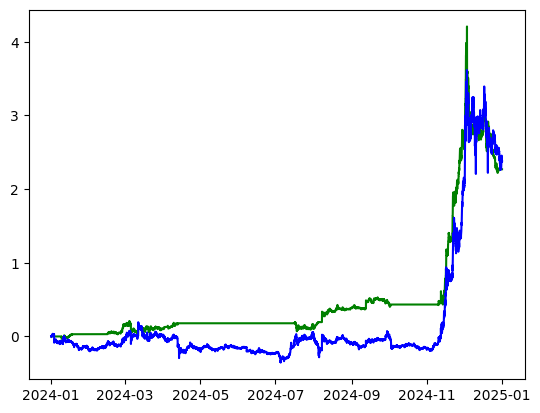

In [147]:
data['strat_rets'] = data['rets']*data['signal']
cum_stratrets = (1+data['strat_rets']).cumprod() -1
cumrets = (1+data['rets']).cumprod() -1
plt.plot(cum_stratrets,color = 'green')
plt.plot(cumrets, color ='blue')
plt.show()

In [148]:
data['signal'].sum()

np.float64(1747.0)